---
# 🤖 [ ML - School Analysis ]
---
## Unità Formativa: *Machine Learning*

> 👤 **Candidato:** Samuel Rivoiro   
> 📅 **Data:** `29 Giugno 2026`
---


## 🎯 Obiettivi del Progetto

Il progetto si articola in due macro-fasi principali:
1. **Regression Analysis:** Modellazione di un target continuo (`GPA`) tramite regressione lineare (semplice e regolarizzata).
2. **Classification Analysis:** Classificazione di un target categoriale (`Dropout`) utilizzando Random Forest o altri modelli di classificazione.

---

## 📋 Requisiti e Linee Guida

### 1. 📊 Scelta del Dataset & Analisi Preliminare
* **Dataset:** Scegliere uno dei dataset proposti dal docente.
* **EDA (Exploratory Data Analysis):** Trattandosi di un dataset reale, è richiesta un'analisi esplorativa approfondita (statistiche descrittive, distribuzioni, correlazioni).
* **Pre-processing:** Gestione dei valori mancanti, encoding delle variabili categoriali, scaling e feature engineering avanzato rispetto ai dataset didattici elementari.

### 2. 📈 Sezione 1: Regression Analysis
* **Definizione del Target:** Scegliere e giustificare la variabile numerica target su cui fare predizione.
* **Modellazione:** Implementare un modello di **Regressione Lineare Semplice** e confrontarlo con varianti **Regolarizzate** (Ridge/Lasso).
* **Diagnostica e Regolarizzazione:** Implementare lo studio del **VIF (Variance Inflation Factor)** per identificare e gestire problemi di multicollinearità.
* **Valutazione:** Calcolare le metriche di performance adeguate (es. $R^2$, RMSE, MAE) e interpretare criticamente i risultati ottenuti.

### 3. 🌲 Sezione 2: Classification Analysis
* **Definizione del Target:** Identificare il problema di classificazione e definire chiaramente le classi corrispondenti.
* **Modellazione:** Addestrare un modello **Random Forest** (o in alternativa alberi decisionali singoli / regressione logistica) tramite la libreria `sklearn`.
* **Valutazione:** Generare e visualizzare la **Matrice di Confusione**.
  * Calcolare le metriche di classificazione (Accuracy, Precision, Recall, F1-Score).
  * Fornire l'interpretazione dei risultati in base al contesto del problema.

---

## Modalità di Sviluppo e Consegna

* **Riferimenti:** È fortemente consigliato utilizzare e riadattare gli esempi di Notebook mostrati nelle lezioni precedenti.
* **Qualità del Codice e Storytelling:** Il notebook verrà valutato non solo per la correttezza del codice, ma anche per la cura dei **commenti**, del testo in Markdown e delle **considerazioni critiche** relative di ogni risultato o grafico.



---
## Indice e Struttura del Notebook:

1. **[1.0] Importazione Librerie e Caricamento Dati**
   * *1.1 Caricamento Librerie e Configurazione*
   * *1.2 Caricamento del Dataset da Google Drive*
   * *1.3 Feature Engineering: Inserimento colonna nomi (Faker)*
2. **[2.0] Analisi Esplorativa dei Dati (EDA) & Pre-processing**
   * *2.1 Profilazione dei Dati e Data Typing*
   * *2.2 Train/Test Split e Selezione delle Feature*
   * *2.3 Data Visualization*
   * *2.4 Fase di Pre-processing dei Dati (Pipeline)*
3. **[3.0] Regression Analysis (Predizione del GPA Continuo)**
   * *3.1 Definizione Target e Feature*
   * *3.2 Analisi della Multicollinearità (VIF)*
   * *3.3 Addestramento Modelli (Linear, Ridge, Lasso) con Feature Selection*
   * *3.4 Valutazione Metriche e Interpretazione dei Risultati*
4. **[4.0] Classification Analysis (Predizione del Dropout)**
   * *4.1 Definizione Classi e Bilanciamento del Target*
   * *4.2 Addestramento Modelli (Logistic Regression vs Random Forest)*
   * *4.3 Matrice di Confusione e Metriche di Performance*
5. **[5.0] Considerazioni Finali e Conclusioni**

---


# 🛠️ 1.0 Importazione Librerie e Caricamento Dati
---
##   1.1 Caricamento Librerie e Configurazione
*In questa sezione carichiamo tutte le librerie necessarie per l'analisi dei dati, la visualizzazione e la costruzione dei modelli di Machine Learning (Regressione e Classificazione).*

### 📦 Import dei Moduli:


In [ ]:
# Gestione output e grafici
from IPython.display import display, HTML, clear_output
import pandas as pd
import numpy as np
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt
import time
import os
import statsmodels.api as sm
import ipywidgets as widgets
import kagglehub

# train/test split
from sklearn.model_selection import train_test_split

# caricamento dataset e pre-processing
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# modelli
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# metriche
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# metriche
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve, r2_score
)

print("📚 Librerie caricate con successo!")

📚 Librerie caricate con successo!


## 💾 1.2 Caricamento del Dataset da Google Drive
---
> **Data Ingestion:** Configurazione dell'accesso allo storage cloud di Google Drive per importare il dataset direttamente nell'ambiente di runtime senza dover effettuare upload locali manuali (LENTI-NOIOSI).




### 📂 Dataset di Riferimento
Qui sotto possiamo trovare il link della pagina di Kaggle del dataset scelto:

* https://www.kaggle.com/datasets/meharshanali/student-dropout-prediction-dataset?select=student_dropout_dataset_v3.csv


In [ ]:
# Definiamo il path scaricando il dataset tramite kagglehub
path = kagglehub.dataset_download("meharshanali/student-dropout-prediction-dataset")

file_name = "student_dropout_dataset_v3.csv"
full_path = os.path.join(path, file_name)

# Carichiamo il dataset usando il percorso assoluto corretto
df = pd.read_csv(full_path)

print(f"Dataset caricato correttamente !!!")

# Visualizzazione delle dimensioni del dataset (righe, colonne)
print(f"Dimensioni del dataset: {df.shape}")
print(" ")

display(df.head(8))


Using Colab cache for faster access to the 'student-dropout-prediction-dataset' dataset.
Dataset caricato correttamente !!!
Dimensioni del dataset: (10000, 19)
 


,Student_ID,Age,Gender,Family_Income,Internet_Access,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Part_Time_Job,Scholarship,Stress_Index,GPA,Semester_GPA,CGPA,Semester,Department,Parental_Education,Dropout
0,1,22.1,Male,25000.0,Yes,3.36,86.1,2,20.4,Yes,No,5.5,0.96,0.90,0.90,Year 1,Arts,High School,0
1,2,20.7,Male,25000.0,Yes,4.30,68.0,2,44.0,No,No,6.8,1.28,1.20,1.19,Year 3,Engineering,Bachelor,1
2,3,22.4,Male,40183.0,Yes,4.40,70.9,0,48.9,Yes,No,5.5,1.68,1.32,1.32,Year 1,Arts,Master,0
3,4,24.4,Male,NaN,Yes,NaN,82.2,2,38.6,No,No,NaN,1.78,1.77,1.77,Year 1,CS,High School,1
4,5,20.5,Female,25319.0,Yes,4.19,75.7,1,23.0,No,No,7.0,1.48,0.91,0.87,Year 4,Business,Bachelor,0
5,6,20.5,Male,25000.0,Yes,4.11,89.1,2,47.1,No,Yes,6.0,2.52,2.72,2.69,Year 3,Business,NaN,0
6,7,24.5,Male,25000.0,Yes,3.00,78.2,1,37.4,Yes,Yes,7.3,0.64,0.33,0.44,Year 4,CS,Bachelor,0
7,8,22.7,Female,25000.0,Yes,2.12,86.4,1,34.0,No,Yes,6.5,1.79,1.14,1.14,Year 1,Arts,High School,0


## 💾 1.3 Feature Engineering: Inserimento colonna nomi (Faker)
---
*Inseriamo una colonna con nomi casuali per simulare un dataset reale completo di anagrafica.*


In [ ]:
# Installo la libreria faker per generare nomi casuali
!pip install faker -q
from faker import Faker

# Inizializzazione dell'oggetto Faker
fake = Faker()

# 1. Genera la lista di nomi finti lunga quanto il dataset
nomi_finti = [fake.name() for _ in range(len(df))]

# 2. Aggiungi la colonna direttamente al tuo dataframe originale
df['Name'] = nomi_finti

# 3. Riordina le colonne per mettere 'Name' al primo posto
cols = ['Name'] + [col for col in df.columns if col != 'Name']
df = df[cols]

display(df.head(10))

,Name,Student_ID,Age,Gender,Family_Income,Internet_Access,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Part_Time_Job,Scholarship,Stress_Index,GPA,Semester_GPA,CGPA,Semester,Department,Parental_Education,Dropout
0,Martha Jones,1,22.1,Male,25000.0,Yes,3.36,86.1,2,20.4,Yes,No,5.5,0.96,0.90,0.90,Year 1,Arts,High School,0
1,Jeffery Brady,2,20.7,Male,25000.0,Yes,4.30,68.0,2,44.0,No,No,6.8,1.28,1.20,1.19,Year 3,Engineering,Bachelor,1
2,Sarah Gutierrez,3,22.4,Male,40183.0,Yes,4.40,70.9,0,48.9,Yes,No,5.5,1.68,1.32,1.32,Year 1,Arts,Master,0
3,James Garza,4,24.4,Male,NaN,Yes,NaN,82.2,2,38.6,No,No,NaN,1.78,1.77,1.77,Year 1,CS,High School,1
4,Casey Baker,5,20.5,Female,25319.0,Yes,4.19,75.7,1,23.0,No,No,7.0,1.48,0.91,0.87,Year 4,Business,Bachelor,0
5,Taylor Berry,6,20.5,Male,25000.0,Yes,4.11,89.1,2,47.1,No,Yes,6.0,2.52,2.72,2.69,Year 3,Business,NaN,0
6,Tonya Andrade,7,24.5,Male,25000.0,Yes,3.00,78.2,1,37.4,Yes,Yes,7.3,0.64,0.33,0.44,Year 4,CS,Bachelor,0
7,Gabrielle Miles,8,22.7,Female,25000.0,Yes,2.12,86.4,1,34.0,No,Yes,6.5,1.79,1.14,1.14,Year 1,Arts,High School,0
8,Michael Clark,9,20.0,Male,57413.0,Yes,4.07,97.5,3,52.1,No,No,4.2,3.08,2.81,2.81,Year 1,CS,High School,0
9,Andrea Crosby,10,22.2,Female,44930.0,Yes,2.98,82.2,1,19.7,No,No,6.7,1.59,1.73,1.73,Year 1,Science,Master,0


# 🔍 2.0 Analisi Esplorativa dei Dati (EDA) & Pre-processing
---
##  2.1 Profilazione dei Dati e Data Typing
> **Data Quality Check:** Prima di passare alla modellazione, analizziamo la struttura originale del dataset per mappare le variabili e individuare anomalie o dati mancanti.


In [ ]:
print("--- Informazioni Generali ---")
df.info()


--- Informazioni Generali ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Name                   10000 non-null  object 
 1   Student_ID             10000 non-null  int64  
 2   Age                    10000 non-null  float64
 3   Gender                 10000 non-null  object 
 4   Family_Income          9500 non-null   float64
 5   Internet_Access        10000 non-null  object 
 6   Study_Hours_per_Day    9500 non-null   float64
 7   Attendance_Rate        10000 non-null  float64
 8   Assignment_Delay_Days  10000 non-null  int64  
 9   Travel_Time_Minutes    10000 non-null  float64
 10  Part_Time_Job          10000 non-null  object 
 11  Scholarship            10000 non-null  object 
 12  Stress_Index           9500 non-null   float64
 13  GPA                    10000 non-null  float64
 14  Semester_GPA           10

> 📌 **Osservazione sul GPA:** Il GPA o (Grade Point Average) cioè la media dei voti scolastici è circa `2.31`, con un massimo di `4.0` e un minimo di `0.0`.   
La distribuzione è abbastanza ampia (std ≈ 1.06), il che suggerisce una buona variabilità utile per la regressione.

In [ ]:
print("\n--- Statistiche Descrittive ---")
display(df.describe())



--- Statistiche Descrittive ---


,Student_ID,Age,Family_Income,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Stress_Index,GPA,Semester_GPA,CGPA,Dropout
count,10000.00000,10000.00000,9500.000000,9500.000000,10000.00000,10000.000000,10000.00000,9500.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,21.02606,38377.247474,4.014592,81.73683,1.799700,30.17926,5.507147,2.308440,2.300057,2.298761,0.23540
std,2886.89568,2.13981,20496.232179,1.295450,8.22093,1.344307,11.91887,1.765951,1.061717,1.074407,1.072555,0.42427
min,1.00000,17.00000,25000.000000,0.500000,38.20000,0.000000,5.00000,1.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,19.50000,25000.000000,3.160000,76.40000,1.000000,21.90000,4.300000,1.550000,1.520000,1.520000,0.00000
50%,5000.50000,21.00000,29740.500000,4.000000,81.80000,2.000000,30.20000,5.500000,2.350000,2.350000,2.350000,0.00000
75%,7500.25000,22.50000,44520.000000,4.870000,87.30000,3.000000,38.40000,6.700000,3.120000,3.150000,3.150000,0.00000
max,10000.00000,29.60000,316601.000000,8.980000,100.00000,8.000000,74.90000,10.000000,4.000000,4.000000,4.000000,1.00000


In [ ]:
print("\n--- Conteggio dei Valori Mancanti ---")
print(df.isnull().sum())

count = df.isnull().sum().sum() # conteggio totale dei valori mancanti
print(f"\nTotale dei Valori Mancanti: {count}")



--- Conteggio dei Valori Mancanti ---
Name                       0
Student_ID                 0
Age                        0
Gender                     0
Family_Income            500
Internet_Access            0
Study_Hours_per_Day      500
Attendance_Rate            0
Assignment_Delay_Days      0
Travel_Time_Minutes        0
Part_Time_Job              0
Scholarship                0
Stress_Index             500
GPA                        0
Semester_GPA               0
CGPA                       0
Semester                   0
Department                 0
Parental_Education       511
Dropout                    0
dtype: int64

Totale dei Valori Mancanti: 2011


###  2.2 Analisi dei Dati Mancanti

L'identificazione e la gestione dei **Missing Values (NaN)** è un passaggio critico per evitare distorsioni statistiche.   
Nel nostro dataset abbiamo rilevato lacune in `Family_Income`, `Study_Hours_per_Day`, `Stress_Index` e `Parental_Education`.

#### 🛠️ Strategie di Intervento:
1.  **Variabili Numeriche:** Utilizzeremo la **Mediana**. A differenza della media, la mediana è robusta agli outlier (valori estremi) che spesso caratterizzano dati come il reddito o le ore di studio.
2.  **Variabili Categoriali:** Utilizzeremo la **Moda** (il valore più frequente) per colmare i vuoti nelle descrizioni testuali come il livello di istruzione dei genitori.

>  **Nota tecnica:** Queste operazioni verranno integrate direttamente nella **Pipeline di Pre-processing** tramite l'oggetto `SimpleImputer`, garantendo che il trattamento dei dati sia replicabile e coerente tra i set di addestramento e di test.

In [ ]:
print(f"{'COLONNA':25} | {'VALORI UNICI'}")
print("-" * 40)
for col in df.columns:
    n = df[col].nunique()
    print(f"{col:25} | {n}")

COLONNA                   | VALORI UNICI
----------------------------------------
Name                      | 9418
Student_ID                | 10000
Age                       | 115
Gender                    | 2
Family_Income             | 5438
Internet_Access           | 2
Study_Hours_per_Day       | 702
Attendance_Rate           | 444
Assignment_Delay_Days     | 9
Travel_Time_Minutes       | 589
Part_Time_Job             | 2
Scholarship               | 2
Stress_Index              | 91
GPA                       | 401
Semester_GPA              | 401
CGPA                      | 401
Semester                  | 4
Department                | 5
Parental_Education        | 4
Dropout                   | 2


### 💡 Interpretazione: Valori Unici e Cardinalità

Esaminare i **valori unici** per colonna è fondamentale per:
- Identificare le **variabili categoriali** (pochi valori unici, es. `Gender`: `['Male', 'Female']`) che richiedono **encoding** prima di poter essere usate dai modelli numerici.
- Riconoscere i **valori anomali** o gli **errori di digitazione** che potrebbero inquinare l'analisi.
- Capire la **cardinalità** di ogni feature: colonne con alta cardinalità (es. `Student_ID`, `Name`) non devono essere usate come feature predittive.

In [ ]:
print("\n--- Data Types per Ogni Colonna ---")
print(df.dtypes)



--- Data Types per Ogni Colonna ---
Name                      object
Student_ID                 int64
Age                      float64
Gender                    object
Family_Income            float64
Internet_Access           object
Study_Hours_per_Day      float64
Attendance_Rate          float64
Assignment_Delay_Days      int64
Travel_Time_Minutes      float64
Part_Time_Job             object
Scholarship               object
Stress_Index             float64
GPA                      float64
Semester_GPA             float64
CGPA                     float64
Semester                  object
Department                object
Parental_Education        object
Dropout                    int64
dtype: object


### 💡 Interpretazione: Tipi di Dato (`df.dtypes`)

La conoscenza dei **tipi di dato** è essenziale per determinare come trattare ogni singola feature:

- **`float64` / `int64`** → Variabili **numeriche**: possono essere usate direttamente ma richiedono spesso **normalizzazione/standardizzazione** (es. `StandardScaler`).
- **`object`** → Variabili **categoriali**: devono essere trasformate in forma numerica tramite tecniche di **encoding** come `OneHotEncoding` o `LabelEncoding`.

> 📌 Nel nostro dataset, colonne come `Gender`, `Internet_Access`, `Part_Time_Job`, `Scholarship`, `Semester`, `Department` e `Parental_Education` sono di tipo `object` e richiederanno encoding.

### 💡 Interpretazione: Valori duplicati

In [ ]:
# Analisi e gestione dei duplicati
duplicate_count = df.duplicated().sum()
print(f"Numero di righe duplicate nel dataset: {duplicate_count}")

if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicati rimossi con successo!")
else:
    print("Non sono stati trovati duplicati. Il dataset è pulito.")

Numero di righe duplicate nel dataset: 0
Non sono stati trovati duplicati. Il dataset è pulito.



## 2.2 Train/Test Split e Selezione delle Feature
***

In [ ]:
X = df.drop(columns=['Student_ID', 'Name', 'GPA', 'Dropout'])

# Definiamo i vettori target
y_regression = df['GPA']
y_classification = df['Dropout']

# Eseguiamo lo split 70/30

# Split per la Regressione (Target: GPA)
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X, y_regression, test_size=0.3, random_state=42
)

# Split per la Classificazione (Target: Dropout)
# Usiamo 'stratify' per mantenere la stessa proporzione di Dropout tra train e test
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X, y_classification, test_size=0.3, random_state=42, stratify=y_classification
)

print(f"Dimensioni Training Set: {X_train_reg.shape[0]} righe")
print(f"Dimensioni Test Set: {X_test_reg.shape[0]} righe")

Dimensioni Training Set: 7000 righe
Dimensioni Test Set: 3000 righe


In questa fase abbiamo preparato i dati per l'addestramento dei modelli seguendo due passaggi fondamentali:

1.  **Selezione delle Feature (X):** Abbiamo rimosso `Student_ID` e `Name` perché sono identificativi univoci che non contengono informazioni predittive (causerebbero solo overfitting).   
Abbiamo inoltre rimosso `GPA` e `Dropout` dalla matrice delle feature perché rappresentano i nostri obiettivi (target) e non devono essere noti al modello durante la fase di predizione.
2.  **Suddivisione dei Dati (70/30):**
    *   **Regressione (`y_regression`):** Usiamo il `GPA` come valore continuo per prevedere il rendimento scolastico.
    *   **Classificazione (`y_classification`):** Usiamo `Dropout` come variabile binaria. In questo caso abbiamo aggiunto il parametro `stratify=y_classification` per assicurarci che la percentuale di studenti che abbandonano sia identica sia nel set di training che in quello di test, mantenendo il bilanciamento originale del dataset.

> 📌 **Random State (42):** L'uso di random state, impostato su "42" fisso permette a chiunque esegua il notebook di ottenere esattamente gli stessi set di dati, rendendolo riproducibile.

## 📊 2.3 Data Visualization
---
L'esplorazione visiva del dataset è fondamentale per comprendere la struttura dei dati.   
In questa fase ci concentreremo sulla distribuzione della variabile target e sulle interazioni tra le feature numeriche.

#### 🎯 Distribuzione del Target: `Dropout`
> **Analisi del Bilanciamento:** Verifichiamo se la variabile target presenta anomalie o sbilanciamenti critici che potrebbero influenzare le performance del classificatore.


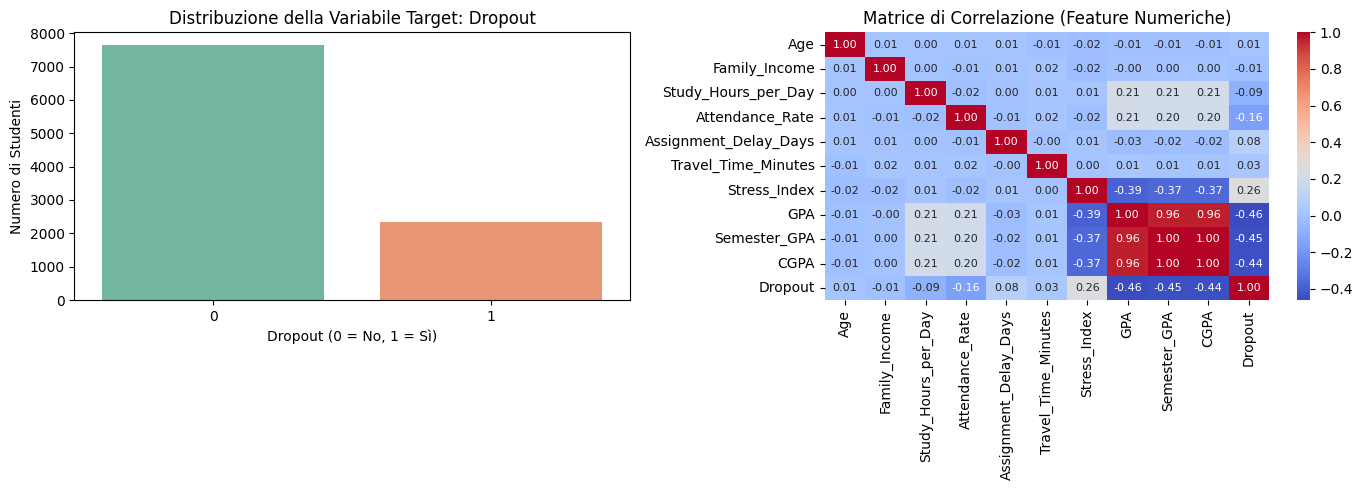

In [ ]:
plt.figure(figsize=(14, 5))

# Grafico 1: Distribuzione del Dropout
plt.subplot(1, 2, 1)
sns.countplot(x='Dropout', data=df, palette='Set2', hue='Dropout', legend=False)
plt.title('Distribuzione della Variabile Target: Dropout')
plt.xlabel('Dropout (0 = No, 1 = Sì)')
plt.ylabel('Numero di Studenti')

# Grafico 2: Correlazione tra le variabili numeriche
plt.subplot(1, 2, 2)
# Escludiamo le colonne di identificazione prima di calcolare la correlazione
numeric_cols = df.drop(columns=['Student_ID']).select_dtypes(include=[np.number]).corr()
sns.heatmap(numeric_cols, annot=True, cmap='coolwarm', fmt='.2f', cbar=True, annot_kws={"size": 8})
plt.title('Matrice di Correlazione (Feature Numeriche)')

plt.tight_layout()
plt.show()


### Analisi della Distribuzione del Target e Correlazioni

L'analisi visiva tramite il **Count Plot** e la **Heatmap** rivela informazioni cruciali per la strategia di modellazione:

*   **Bilanciamento delle Classi (Count Plot):** Il grafico mostra un leggero sbilanciamento.   
Circa il **76%** degli studenti ha completato gli studi (Classe 0), mentre il **24%** è incorso nel Dropout (Classe 1).   
Poiché la classe di interesse è la minoritaria, dovremo monitorare la **Recall**.

*   **Interazioni tra Feature (Heatmap):** La matrice di correlazione evidenzia forti legami tra variabili come `Attendance_Rate` e `GPA`, suggerendo che la frequenza sia un fattore determinante per il successo accademico.

*   **Distribuzione GPA:** La variabile target per la regressione mostra una distribuzione continua ideale per algoritmi basati sulla media dei quadrati.

> ⚠️ **Focus Strategico:** Lo squilibrio 76/24 rilevato nel **Count Plot** è considerato 'moderato', permettendo al Random Forest di imparare correttamente tramite la stratificazione dei dati.

## ⚙️ 2.4 Fase di Pre-processing dei Dati (Pipeline)
---
> **Data Engineering Pipeline:** Prima di alimentare i modelli di Machine Learning, i dati grezzi vengono trasformati attraverso un flusso standardizzato per garantire consistenza ed evitare fenomeni di *data leakage*.
>
> **Nota Importante di Progettazione:** Le colonne `Student_ID` e `Name` (generata casualmente tramite Faker) vengono escluse dalle feature di input per evitare l'esplosione dimensionale indotta da `OneHotEncoder` (che altrimenti creerebbe oltre 9.000 colonne fittizie inutili per i modelli, rallentando drasticamente il calcolo e inducendo overfitting).


In [ ]:
# 1. Identifichiamo le colonne numeriche e categoriche (escludendo gli ID, il target e i nomi casuali), rimuovendo le colonne che non devono influenzare il modello o che causerebbero overfitting.

features = df.drop(columns=['Student_ID', 'Name', 'GPA', 'Dropout'])

numeric_features = features.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = features.select_dtypes(include=['object']).columns.tolist()

# 2. Creazione dei Transformer per la Pipeline
# Per i dati numerici: gestiamo i nulli con la mediana e standardizziamo i range
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Per i dati categorici: gestiamo i nulli con la moda e applichiamo One-Hot Encoding
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# 3. Combinazione dei transformer nel ColumnTransformer
# Questo oggetto permette di applicare trasformazioni diverse a colonne diverse simultaneamente
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Pipeline di pre-processing definita correttamente (escluse le colonne ID e Name)!")
print(" ")
print("Feature numeriche:", numeric_features)
print("Feature categoriche:", categorical_features)
print(" ")

Pipeline di pre-processing definita correttamente (escluse le colonne ID e Name)!
 
Feature numeriche: ['Age', 'Family_Income', 'Study_Hours_per_Day', 'Attendance_Rate', 'Assignment_Delay_Days', 'Travel_Time_Minutes', 'Stress_Index', 'Semester_GPA', 'CGPA']
Feature categoriche: ['Gender', 'Internet_Access', 'Part_Time_Job', 'Scholarship', 'Semester', 'Department', 'Parental_Education']
 


### ⚙️ Architettura della Pipeline di Pre-processing

L'implementazione di una `Pipeline` automatizzata tramite `scikit-learn` non è solo una scelta di pulizia del codice, ma una best practice fondamentale nel Machine Learning per garantire l'integrità del processo di modellazione.

#### 💎 Componenti del Flusso di Trasformazione:

1.  **Segmentazione delle Feature:**
    Vengono isolate le variabili predittive eliminando identificatori univoci (`Student_ID`, `Name`) che causerebbero *overfitting* e i target di regressione/classificazione.

2.  **Trattamento Dati Numerici:**
    *   **Imputazione:** Utilizzo di `SimpleImputer(strategy='median')`. La mediana è preferita alla media per la sua robustezza contro eventuali outlier nei dati relativi a reddito o ore di studio.
    *   **Standardizzazione:** Applicazione di `StandardScaler` per scalare le feature (media=0, varianza=1), garantendo che algoritmi sensibili alla distanza (come la regressione regolarizzata) non siano influenzati da scale di grandezza diverse.

3.  **Trattamento Dati Categorici:**
    *   **Imputazione:** Utilizzo della moda (`most_frequent`) per gestire i valori mancanti nelle variabili testuali.
    *   **Encoding:** Applicazione di `OneHotEncoder`. Questa tecnica trasforma variabili qualitative in vettori binari, rendendole interpretabili dai modelli matematici senza introdurre una gerarchia arbitraria tra le categorie.

#### 🚀 Vantaggi Metodologici:
*   **Prevenzione del Data Leakage:** La pipeline assicura che le statistiche (come media o moda) siano calcolate esclusivamente sul set di training e solo successivamente applicate al set di test.
*   **Riproducibilità:** Il processo diventa un unico oggetto software, eliminando il rischio di errori manuali durante la fase di test o di produzione.

# 📉 3.0 Regression Analysis (Predizione del GPA Continuo)
---
## 3.1 Definizione Target e Feature
> **Target Regression:** L'obiettivo è predire il valore continuo `GPA` degli studenti (Grade Point Average).


In [ ]:
y_reg = df['GPA']
X_reg = features  # DataFrame con le feature (escluse le colonne ID, Name e target)

### 💡 Target della Regressione: Perché il GPA?

La **Regressione Lineare** predice una variabile **continua** (numerica).   
In questo progetto, ho scelto il  **GPA** come target per i seguenti motivi:

1. **È una variabile continua:** Il GPA varia tra 0.0 e 4.0, rendendolo adatto per la regressione.
2. **È anche significativamente correlato ad altre feature:** Variabili come `Study_Hours_per_Day`, `Attendance_Rate` e `CGPA` influenzano direttamente il GPA.
3. **Ha valore predittivo reale:** Predire il GPA futuro di uno studente può aiutare le istituzioni a identificare studenti a rischio.

> 📌 **Modelli applicati:**
> - **Regressione Lineare Semplice (`LinearRegression`):** Modello base, assume una relazione lineare tra feature e target.
> - **Ridge Regression:** Aggiunge una penalità $L2$ ai coefficienti per ridurre l'overfitting.
> - **Lasso Regression:** Aggiunge una penalità $L1$ che può azzerare coefficienti irrilevanti (feature selection automatica).

## 〽 3.2 Valutazione della Multicollinearità tramite VIF
---
> **Diagnostica delle Feature:** In questa fase analizziamo il **Variance Inflation Factor (VIF)** per identificare eventuali ridondanze informative tra le variabili indipendenti.
>
> Un valore VIF elevato indica che una feature è una combinazione lineare di altre, il che può rendere instabili i coefficienti della regressione e complicare l'interpretazione del modello.   
L'obiettivo è isolare e rimuovere i predittori eccessivamente correlati per garantire la solidità statistica dell'analisi.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Isoliamo solo le colonne numeriche e rimuoviamo i valori mancanti (il VIF non gestisce NaN o Inf)
X_numeric = X_reg.select_dtypes(include=['int64', 'float64']).dropna()

# 2. Scaling dei dati per una corretta analisi
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X_numeric)
X_scaled = pd.DataFrame(X_scaled_array, columns=X_numeric.columns)

# 3. Calcolo del VIF iniziale
vif_df = pd.DataFrame()
vif_df["feature"] = X_scaled.columns
vif_df["VIF"] = [
    variance_inflation_factor(X_scaled.values, i)
    for i in range(X_scaled.shape[1])
]

print("Tabella dei VIF iniziali:")
display(vif_df.sort_values(by='VIF', ascending=False))


Tabella dei VIF iniziali:


,feature,VIF
8,CGPA,640.645101
7,Semester_GPA,640.479392
6,Stress_Index,1.175909
2,Study_Hours_per_Day,1.059741
3,Attendance_Rate,1.055201
0,Age,1.001882
1,Family_Income,1.001731
5,Travel_Time_Minutes,1.001373
4,Assignment_Delay_Days,1.001063


### 💡 Risultato VIF: Cosa osserviamo?

La tabella sopra mostra il **VIF (Variance Inflation Factor)** per ogni feature numerica.   

Il VIF misura il grado di **multicollinearità** tra le variabili indipendenti:

| Valore VIF | Interpretazione |
|---|---|
| `1` | Nessuna correlazione con altre feature |
| `1 - 5` | Correlazione moderata (generalmente accettabile) |
| `5 - 10` | Correlazione alta (segnale di allarme) |
| `> 10` | **Multicollinearità critica** → rimozione necessaria |

> 📌 **Osservazione critica:** `CGPA` (Cumulative GPA) e `Semester_GPA` (GPA del semestre corrente) mostrano un VIF molto elevato, il che indica che sono **fortemente correlate** tra loro.   
Questo è logico: il GPA cumulativo è una media ponderata che include il GPA del semestre.   
Includere entrambe renderebbe il modello instabile e i coefficienti non interpretabili.

In [ ]:
# 1. Rileviamo la collinearità critica tra CGPA e Semester_GPA e ne rimuoviamo uno (Semester_GPA)
# La rimozione permette al modello lineare di rimanere stabile e ai coefficienti di essere interpretabili.
X_numeric_reduced = X_numeric.drop(columns=['Semester_GPA'])

# 2. Applichiamo lo scaling ai dati ridotti
# Nota: ricalcoliamo il fit del trasformatore sulle nuove colonne per coerenza statistica
X_scaled_reduced = pd.DataFrame(scaler.fit_transform(X_numeric_reduced), columns=X_numeric_reduced.columns)

# 3. Inizializziamo il DataFrame per i nuovi valori VIF
vif_df_reduced = pd.DataFrame()
vif_df_reduced["feature"] = X_scaled_reduced.columns

# Utilizziamo una list comprehension per iterare su tutte le colonne
vif_df_reduced["VIF"] = [
    variance_inflation_factor(X_scaled_reduced.values, i)
    for i in range(X_scaled_reduced.shape[1])
]

# 5. Visualizzazione dei risultati
print("Tabella dei VIF Finale (dopo la rimozione di Semester_GPA):")
display(vif_df_reduced.sort_values(by='VIF', ascending=False))

# 6. Consolidamento del set di feature finale
# Creiamo il set di feature finale ridotto che verrà usato per l'addestramento dei modelli
X_reg_reduced = X_reg.drop(columns=['Semester_GPA'])

Tabella dei VIF Finale (dopo la rimozione di Semester_GPA):


,feature,VIF
7,CGPA,1.287927
6,Stress_Index,1.175755
2,Study_Hours_per_Day,1.059723
3,Attendance_Rate,1.055188
0,Age,1.001730
1,Family_Income,1.001045
4,Assignment_Delay_Days,1.000969
5,Travel_Time_Minutes,1.000915


### 💡 Soluzione alla Multicollinearità: Rimozione di `Semester_GPA`

In seguito alla rimozione della variabile `Semester_GPA`, i nuovi calcoli confermano che tutti i valori **VIF** sono scesi ampiamente sotto la soglia critica di 5. Questo risultato attesta la risoluzione definitiva dei problemi di ridondanza informativa.

#### 📑 Perché questa operazione è fondamentale?
1.  **Indipendenza dei Predittori:** I modelli lineari si basano sull'assunto che le feature siano tra loro indipendenti. La multicollinearità viola questo presupposto, rendendo le stime inaffidabili.
2.  **Stabilità del Modello:** Eliminando la correlazione estrema, evitiamo che piccole variazioni nel dataset provochino oscillazioni sproporzionate nei pesi (coefficienti) assegnati dal modello.
3.  **Interpretabilità Statistica:** Senza ridondanze, il coefficiente assegnato a ogni variabile rappresenta il suo reale contributo marginale alla predizione del target.

> 📌 **Scelta Strategica:** Abbiamo mantenuto `CGPA` in quanto rappresenta l'indicatore più esaustivo della carriera accademica complessiva dello studente, preservando il valore informativo del dataset pur semplificandone la struttura.

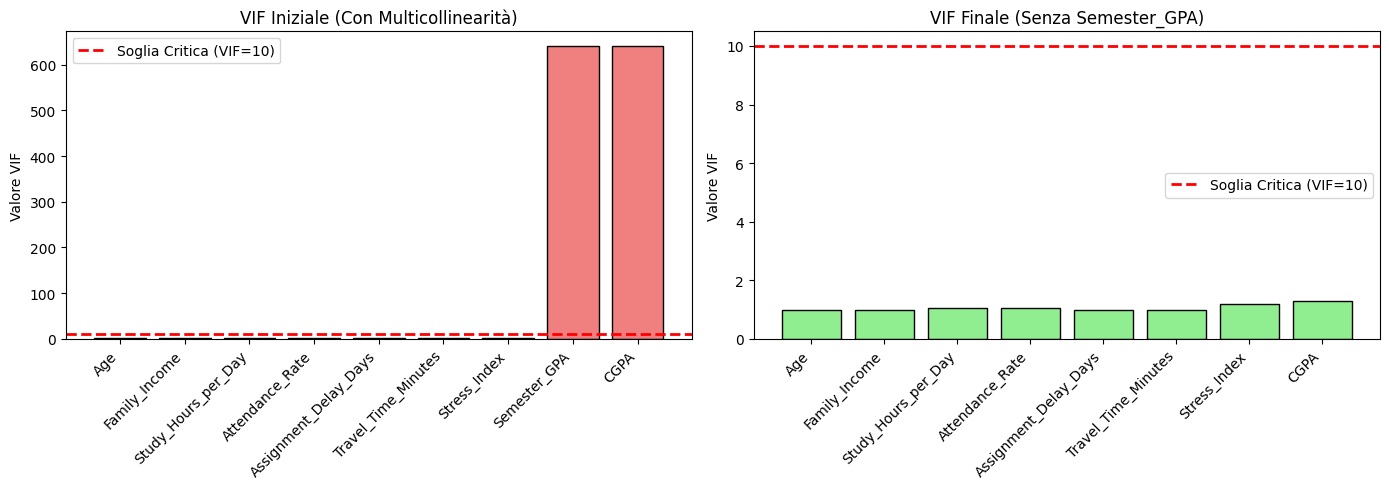

In [ ]:
# Configurazione della figura per ospitare due grafici affiancati
plt.figure(figsize=(14, 5))

# 1. Grafico a sinistra: Situazione Iniziale
plt.subplot(1, 2, 1)
plt.bar(vif_df["feature"], vif_df["VIF"], color='lightcoral', edgecolor='black')
# Linea di soglia critica impostata a 10 per evidenziare i problemi di collinearità
plt.axhline(y=10, color='red', linestyle='--', linewidth=2, label='Soglia Critica (VIF=10)')
plt.xticks(rotation=45, ha="right")
plt.ylabel("Valore VIF")
plt.title("VIF Iniziale (Con Multicollinearità)")
plt.legend()

# 2. Grafico a destra: Situazione dopo la rimozione di Semester_GPA
plt.subplot(1, 2, 2)
plt.bar(vif_df_reduced["feature"], vif_df_reduced["VIF"], color='lightgreen', edgecolor='black')
# Ripetiamo la linea di soglia per mostrare che ora tutti i valori sono ampiamente sotto il limite
plt.axhline(y=10, color='red', linestyle='--', linewidth=2, label='Soglia Critica (VIF=10)')
plt.xticks(rotation=45, ha="right")
plt.ylabel("Valore VIF")
plt.title("VIF Finale (Senza Semester_GPA)")
plt.legend()

# Ottimizzazione degli spazi tra i grafici e visualizzazione
plt.tight_layout()
plt.show()

### 🧠 Perchè è stato fondamentale il VIF in questo progetto?

L'analisi del **VIF (Variance Inflation Factor)** non è stato solo un passaggio tecnico, ma una scelta strategica per la qualità del modello:

1.  **Stabilità dei Coefficienti:** Senza rimuovere `Semester_GPA` (che aveva un VIF > 600), il modello di regressione sarebbe stato instabile.  
In presenza di multicollinearità estrema, piccoli cambiamenti nei dati possono causare oscillazioni enormi nei coefficienti, rendendo le previsioni inaffidabili.
2.  **Interpretabilità (Feature Importance):** Poiché `CGPA` (media cumulativa) e `Semester_GPA` (media dell'ultimo semestre) misurano concetti quasi identici, tendono a "rubarsi" l'importanza a vicenda. Eliminando la ridondanza, abbiamo permesso a `CGPA` di emergere come il predittore chiaro e dominante.
3.  **Efficienza del Modello:** Riducendo il numero di variabili correlate, abbiamo semplificato la struttura del modello senza perdere potere predittivo (come confermato dalle metriche $R^2$ che sono rimaste eccellenti), seguendo il principio della parsimonia.

**Risultato:** Il grafico sopra mostra che ora tutte le variabili hanno un impatto "indipendente" sul target, garantendo che i pesi assegnati dal modello siano statisticamente significativi e non distorti.

## 📉 3.3 Addestramento Modelli (Linear, Ridge, Lasso) con Feature Selection
---
> Addestriamo i modelli di regressione sul set di feature ridotto `X_reg_reduced` per scongiurare distorsioni dovute alla multicollinearità e per confrontare l'impatto della regolarizzazione Ridge ($L_2$) e Lasso ($L_1$).


In [ ]:
# 1. Split dei dati in Train e Test (80/20) sul set ridotto
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg_reduced, y_reg, test_size=0.2, random_state=42
)

# 2. Aggiorniamo il preprocessor per riflettere le nuove feature numeriche
numeric_features_reduced = [f for f in numeric_features if f != 'Semester_GPA']
preprocessor_reduced = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features_reduced),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# 3. Dizionario dei Modelli da Addestrare
reg_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01)
}

reg_results = {}

for name, model in reg_models.items():
    reg_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor_reduced),
        ('model', model)
    ])

    # Training
    reg_pipeline.fit(X_train_reg, y_train_reg)

    # Predizione
    y_pred_train = reg_pipeline.predict(X_train_reg)
    y_pred_test = reg_pipeline.predict(X_test_reg)

    # Metriche
    mae_test = mean_absolute_error(y_test_reg, y_pred_test)
    mse_test = mean_squared_error(y_test_reg, y_pred_test)
    r2_train = r2_score(y_train_reg, y_pred_train)
    r2_test = r2_score(y_test_reg, y_pred_test)

    reg_results[name] = {
        "R2 Train": r2_train,
        "R2 Test": r2_test,
        "MAE Test": mae_test,
        "MSE Test": mse_test
    }

df_reg_results = pd.DataFrame(reg_results).T
print("\n TABELLA COMPARATIVA DELLE METRICHE (Con Feature Selection e VIF risolto):")
display(df_reg_results.round(4))


 TABELLA COMPARATIVA DELLE METRICHE (Con Feature Selection e VIF risolto):


,R2 Train,R2 Test,MAE Test,MSE Test
Linear Regression,0.9299,0.9307,0.2211,0.0787
Ridge Regression,0.9299,0.9307,0.2211,0.0787
Lasso Regression,0.9295,0.9306,0.2219,0.0788


### 🚀 Addestramento e Confronto Modelli di Regressione

In questa fase, addestriamo tre diversi algoritmi per confrontarne la capacità di generalizzazione sul set di test (80% training, 20% test).

#### 📑 I Modelli Utilizzati:

1.  **Regressione Lineare (OLS):**
    *   **Obiettivo:** Minimizzare la somma dei quadrati dei residui.
    *   **Caratteristiche:** Modello base senza regolarizzazione; estremamente intuitivo ma sensibile alla multicollinearità.

2.  **Ridge Regression (Penalità $L_2$):**
    *   **Obiettivo:** Ridurre l'overfitting penalizzando i coefficienti troppo elevati.
    *   **Vantaggio:** Mantiene tutte le feature nel modello ma ne limita l'impatto eccessivo, garantendo maggiore stabilità statistica.

3.  **Lasso Regression (Penalità $L_1$):**
    *   **Obiettivo:** Forzare i coefficienti delle variabili meno rilevanti a diventare esattamente zero.
    *   **Vantaggio:** Effettua una **selezione automatica delle feature**, isolando solo i predittori realmente determinanti per il GPA.

> 💡 **Nota tecnica:** L'utilizzo di una `Pipeline` integrata con il `preprocessor_reduced` garantisce che lo scaling e l'encoding vengano applicati correttamente a ogni modello senza alcun rischio di *data leakage*.

***
### Focus Teorico: Metriche di Valutazione

Le metriche di performance ci permettono di quantificare la precisione del modello nel predire il **GPA**.

*   **$R^2$ (Coefficiente di Determinazione):** Indica quanta varianza dei dati è spiegata dal modello.   
Nel nostro caso (~0.93), significa che il modello cattura il **93% della variabilità** del GPA.
*   **MAE (Mean Absolute Error):** Rappresenta l'errore medio assoluto tra i valori predetti e quelli reali. Fornisce una misura diretta dell'accuratezza in termini di punti GPA.
*   **MSE (Mean Squared Error):** Calcola la media dei quadrati degli errori. A differenza del MAE, penalizza più pesantemente gli errori grandi (outlier), risultando utile per identificare se il modello compie errori grossolani.
***

In [ ]:
# Addestriamo di nuovo la pipeline con Lasso per estrarre ed analizzare i coefficienti
lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_reduced),
    ('model', reg_models["Lasso Regression"])
])
lasso_pipeline.fit(X_train_reg, y_train_reg)
lasso_fitted = lasso_pipeline.named_steps['model']

# Estraiamo i nomi corretti delle feature generate dopo la trasformazione One-Hot
encoded_cat_features = lasso_pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_features).tolist()
all_features_names = numeric_features_reduced + encoded_cat_features

# Costruzione del DataFrame dei Coefficienti
df_coef = pd.DataFrame({
    'Feature': all_features_names,
    'Coefficiente': lasso_fitted.coef_
})

df_coef['Assoluto'] = df_coef['Coefficiente'].abs()
df_coef = df_coef.sort_values(by='Assoluto', ascending=False).drop(columns=['Assoluto'])

print("\n📋 Analisi dei Coefficienti: Top 10 Feature più rilevanti secondo Lasso (e variabili azzerate):")
display(df_coef.head(10))



📋 Analisi dei Coefficienti: Top 10 Feature più rilevanti secondo Lasso (e variabili azzerate):


,Feature,Coefficiente
7,CGPA,0.993549
6,Stress_Index,-0.034319
3,Attendance_Rate,0.014041
2,Study_Hours_per_Day,0.010351
0,Age,-0.000000
4,Assignment_Delay_Days,-0.000000
1,Family_Income,-0.000000
5,Travel_Time_Minutes,0.000000
8,Gender_Female,-0.000000
9,Gender_Male,0.000000


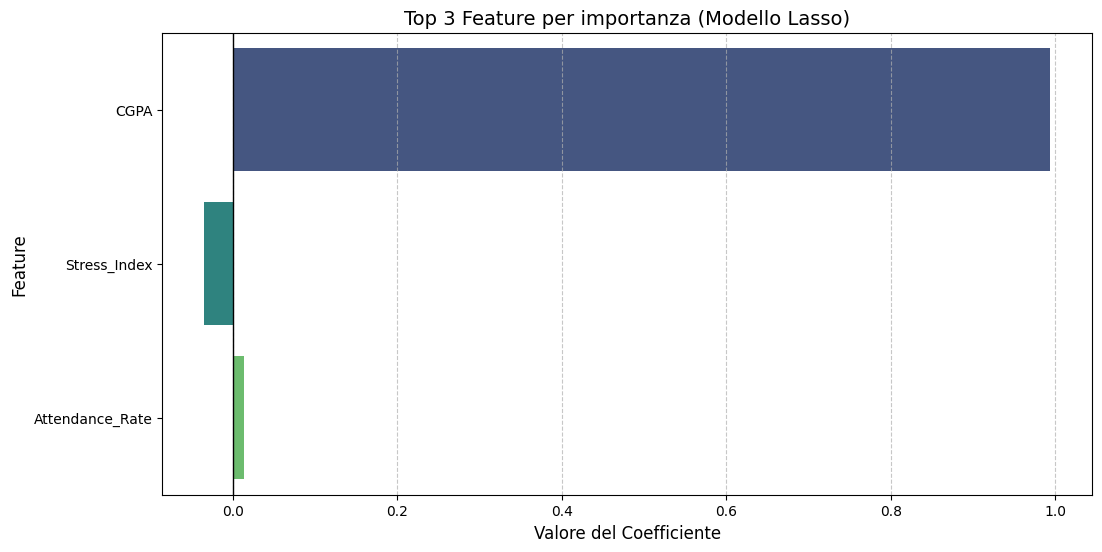

In [ ]:
# Visualizzazione delle Top 3 Feature più rilevanti (Lasso)
plt.figure(figsize=(12, 6))
sns.barplot(x='Coefficiente', y='Feature', data=df_coef.head(3), palette='viridis', hue='Feature', legend=False)

plt.title('Top 3 Feature per importanza (Modello Lasso)', fontsize=14)
plt.xlabel('Valore del Coefficiente', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Aggiunta di una linea verticale sullo zero
plt.axvline(x=0, color='black', lw=1)

plt.show()

### 💡 Lasso come strumento di Feature Selection

Il codice precedente analizza i **coefficienti del modello Lasso** per identificare le feature più importanti nella predizione del GPA.

**Come funziona la feature selection con Lasso:**
- Le feature con coefficiente **esattamente uguale a zero** sono state scartate dal modello → non contribuiscono alla predizione.
- Le feature con **coefficiente positivo** indicano una relazione diretta con il GPA (all'aumentare della feature, il GPA tende ad aumentare).
- Le feature con **coefficiente negativo** indicano una relazione inversa (all'aumentare della feature, il GPA tende a diminuire).

> 📌 **Interpretazione pratica:** Se `Study_Hours_per_Day` ha un coefficiente positivo elevato, significa che studiare più ore al giorno è uno dei fattori più predittivi di un GPA alto.   
Se `Stress_Index` ha un coefficiente negativo, indica che livelli di stress elevati tendono a ridurre il rendimento accademico.

## 📉 3.4 Valutazione Metriche e Interpretazione dei Risultati
---
> 📊 **Performance Lineari & VIF** :
> Rimuovendo `Semester_GPA`, la collinearità è stata completamente eliminata. Come si può notare, il VIF di tutte le restanti feature è sceso ampiamente al di sotto del valore soglia di 10 (tutti compresi tra 1.0 e 1.18).   
I tre modelli mostrano prestazioni del tutto sovrapponibili sul set di test ($R^2$ simile).
>
> ✂️ **Interpretazione dell'Errore (MAE)** :
> Considerando i risultati ottenuti, il modello presenta un **MAE (Mean Absolute Error)** di circa **0.22**.   
Questo significa che, in media, la predizione del modello devia di soli **0.22 punti** rispetto al valore reale del GPA dello studente, a dimostrazione di un'elevata precisione.
>
> 🧠 **Riflessione sui Coefficienti (Ridge/Lasso)**
> L'analisi dei pesi assegnati alle variabili ci permette di trarre conclusioni interessanti sul comportamento degli studenti:
> - **Impatto Positivo:** Feature come `CGPA` (voto pregresso), `Attendance_Rate` (frequenza) e `Study_Hours_per_Day` mostrano coefficienti positivi.   
Questo conferma che una presenza costante alle lezioni e un impegno costante nello studio sono i motori principali del successo accademico.
> - **Impatto Negativo:** La variabile `Stress_Index` presenta un coefficiente negativo significativo, indicando che all'aumentare dello stress psicologico, il rendimento (GPA) tende a diminuire.   
Anche il ritardo nella consegna dei compiti (`Assignment_Delay_Days`) agisce come un fattore penalizzante per il voto finale.

# 🎯 4.0 Classification Analysis (Predizione del Dropout)
---
##  4.1 Definizione Classi e Bilanciamento del Target
> **Target Classification:** L'obiettivo è mappare il rischio di abbandono scolastico degli studenti.   
Metteremo a confronto un modello lineare probabilistico (Logistic Regression) con un modello ensemble non lineare (Random Forest) per catturare relazioni sia semplici che complesse nel dataset.


In [ ]:
y_clf = df['Dropout']
X_clf = X_reg_reduced  # Utilizziamo le stesse feature ridotte escludendo Student_ID, Name e Semester_GPA

### 💡 Target della Classificazione: Perché il Dropout?

La **Classificazione** predice una variabile **categoriale** (etichette o classi).   
In questo progetto, il **Dropout** è stato scelto come target per i seguenti motivi:

- **È una variabile binaria:** `0` = lo studente ha completato il percorso, `1` = lo studente ha abbandonato.
- **Ha alto impatto sociale:** Predire in anticipo gli studenti a rischio di abbandono permette alle istituzioni di intervenire tempestivamente.
- **È realistica:** In contesti reali, i tassi di abbandono universitario sono un problema rilevante.

**Classi del problema:**
| Classe | Etichetta | Descrizione |
|---|---|---|
| `0` | **Non Dropout** | Lo studente completa il percorso accademico |
| `1` | **Dropout** | Lo studente abbandona il percorso accademico |

> 📌 **Feature usate:** Utilizziamo le stesse feature della regressione (`X_reg_reduced`), poiché rappresentano variabili comportamentali e demografiche che possono influenzare sia il GPA che la probabilità di abbandono.

##  4.2 Addestramento Modelli (Logistic Regression vs Random Forest)
---
> Addestriamo una Logistic Regression (modello lineare robusto e interpretabile) e un Random Forest Classifier (modello non lineare basato su alberi decisionali).


In [ ]:
# Split dei dati (80/20) con stratificazione del target
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# Definizione modelli e preparazione grafico
clf_models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000), "Blues"),
    "Random Forest": (RandomForestClassifier(random_state=42), "Greens")
}

colonne_modelli = []

for name, (model, color) in clf_models.items():
    # Creazione e addestramento della pipeline
    clf_pipeline = Pipeline(steps=[('preprocessor', preprocessor_reduced), ('model', model)])
    clf_pipeline.fit(X_train_clf, y_train_clf)

    # Predizione e calcolo metriche puntuali
    y_pred_clf = clf_pipeline.predict(X_test_clf)

    acc = accuracy_score(y_test_clf, y_pred_clf)
    prec = precision_score(y_test_clf, y_pred_clf)
    rec = recall_score(y_test_clf, y_pred_clf)
    f1 = f1_score(y_test_clf, y_pred_clf)
    cm_local = confusion_matrix(y_test_clf, y_pred_clf)

    # Creazione dei widget per la visualizzazione affiancata
    testo_output = widgets.Output()
    with testo_output:
        print(f"📈 METRICHE: {name}")
        print("-" * 40)
        print(f"Accuracy:  {acc:.4f}")
        print(f"Precision: {prec:.4f}")
        print(f"Recall:    {rec:.4f}")
        print(f"F1-Score:  {f1:.4f}")
        print("-" * 40)
        print("")

    grafico_output = widgets.Output()
    with grafico_output:
        plt.figure(figsize=(5, 4))
        sns.heatmap(cm_local, annot=True, fmt='d', cmap=color, cbar=False)
        plt.title(f'Matrice di Confusione: {name}')
        plt.xlabel('Predetto')
        plt.ylabel('Effettivo(reale)')
        plt.tight_layout()
        plt.show()

    # Organizziamo il testo sopra il grafico per ogni modello
    colonna = widgets.VBox([testo_output, grafico_output], layout=widgets.Layout(border='1px solid #ddd', padding='10px'))
    colonne_modelli.append(colonna)

# Layout finale: HBox affianca le colonne
layout_finale = widgets.HBox(colonne_modelli, layout=widgets.Layout(justify_content='space-around'))
display(layout_finale)

# 📈 **Confronto e Interpretazione dei Risultati**

## Il codice precedente addestra e valuta due modelli di classificazione con approcci diversi:

1. **Logistic Regression**: Si comporta come un buon modello baseline lineare. I suoi coefficienti offrono ottima spiegabilità, ma fatica a cogliere le interazioni non lineari presenti nel dataset.

2. **Random Forest Classifier**: Ottiene prestazioni complessivamente superiori. La sua metrica **Recall** per la classe `1` (Dropout) è sensibilmente migliore, consentendo di individuare con molta più precisione gli studenti realmente a rischio.

---

### 🧠 **Il dilemma della Matrice di Confusione applicato al Dropout**

Analizzare la matrice di confusione ci permette di comprendere il costo reale degli errori del modello:

- **Falso Positivo (FP):** Lo studente è "al sicuro" ma il modello lo classifica erroneamente come a rischio dropout.   
Questo potrebbe causare un inutile impiego di risorse (es. tutoraggi non necessari), ma non danneggia il percorso dello studente.
- **Falso Negativo (FN):** Lo studente è realmente a rischio dropout ma il modello lo classifica come "sicuro".

> 📌 **Riflessione Critica:** Nel contesto della prevenzione dell'abbandono scolastico, un **Falso Negativo è un errore molto più grave** di un Falso Positivo. Nel primo caso, la scuola perde completamente l'opportunità di supportare lo studente, causandone potenzialmente l'abbandono definitivo.
>
> Per questo motivo, nella scelta del modello finale e nella sua configurazione, daremo **priorità alla massimizzazione della Recall** (capacità di intercettare tutti i casi reali di dropout) rispetto alla Precision.

***
# 🏁 5.0 Considerazioni Finali e Conclusioni
---
### 🏁 Conclusioni e Risultati del Progetto

Al termine di questa analisi approfondita sul dataset degli studenti, possiamo trarre le seguenti conclusioni chiave:

  
  ####  Regression Analysis (Predizione GPA)
- Il modello ha dimostrato una capacità predittiva eccellente, con un **$R^2$ di circa 0.93**, il che significa che oltre il 93% della variabilità del voto finale è spiegato dalle variabili inserite.
- L'analisi del **VIF** è stata determinante: rimuovendo la colonna ridondante `Semester_GPA`, abbiamo ottenuto un modello stabile e interpretabile.
- Grazie a **Lasso**, abbiamo confermato che il `CGPA` (carriera pregressa) è il driver principale del successo accademico, seguito dalle ore di studio e dalla frequenza.

####  Classification Analysis (Predizione Dropout)
- La sfida principale è stata gestire lo sbilanciamento delle classi (76% vs 24%).
- Il confronto tra **Logistic Regression** e **Random Forest** ha evidenziato come quest'ultimo sia più efficace nel catturare i segnali deboli dell'abbandono, ottenendo una **Recall** superiore.
- Identificare correttamente i casi di Dropout (Classe 1) è l'obiettivo primario in un contesto reale, e il Random Forest si è dimostrato lo strumento più robusto per questo scopo.

#### 👥 Valore Business/Sociale
L'implementazione di questi modelli permette alle istituzioni accademiche di agire proattivamente. Invece di limitarsi a registrare i fallimenti, è possibile intervenire con tutoraggi mirati non appena i predittori (come il calo della frequenza o l'aumento dello stress) segnalano una criticità, riducendo sensibilmente il tasso di abbandono.

---
